In [4]:
# Core
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, ttest_ind, mannwhitneyu, shapiro, levene

# Plotting
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

# Multicollinearity check
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

# ANN
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout
from keras.optimizers import Adam

# Evaluation
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                              recall_score, f1_score, roc_auc_score, roc_curve)
from statsmodels.stats.contingency_tables import mcnemar

# Model explainability
import shap

# Data loading
from ucimlrepo import fetch_ucirepo

# Cleanliness
import warnings
warnings.filterwarnings('ignore')

print("All imports successful!")

c:\Users\ssang\OneDrive\Desktop\bank-marketing-classification\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All imports successful!


In [5]:
pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
bank_marketing = fetch_ucirepo(id=222) 
  
# data (as pandas dataframes) 
X = bank_marketing.data.features 
y = bank_marketing.data.targets 
  
# metadata 
print(bank_marketing.metadata) 
  
# variable information 
print(bank_marketing.variables) 


{'uci_id': 222, 'name': 'Bank Marketing', 'repository_url': 'https://archive.ics.uci.edu/dataset/222/bank+marketing', 'data_url': 'https://archive.ics.uci.edu/static/public/222/data.csv', 'abstract': 'The data is related with direct marketing campaigns (phone calls) of a Portuguese banking institution. The classification goal is to predict if the client will subscribe a term deposit (variable y).', 'area': 'Business', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 45211, 'num_features': 16, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Occupation', 'Marital Status', 'Education Level'], 'target_col': ['y'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2014, 'last_updated': 'Fri Aug 18 2023', 'dataset_doi': '10.24432/C5K306', 'creators': ['S. Moro', 'P. Rita', 'P. Cortez'], 'intro_paper': {'ID': 277, 'type': 'NATIVE', 'title': 'A data-driven approach to predict the s

In [7]:
# Combine features and target into one dataframe
df = pd.concat([X, y], axis=1)

# Check shape
print("Shape:", df.shape)

# View first 5 rows
df.head()

Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   age          45211 non-null  int64
 1   job          44923 non-null  str  
 2   marital      45211 non-null  str  
 3   education    43354 non-null  str  
 4   default      45211 non-null  str  
 5   balance      45211 non-null  int64
 6   housing      45211 non-null  str  
 7   loan         45211 non-null  str  
 8   contact      32191 non-null  str  
 9   day_of_week  45211 non-null  int64
 10  month        45211 non-null  str  
 11  duration     45211 non-null  int64
 12  campaign     45211 non-null  int64
 13  pdays        45211 non-null  int64
 14  previous     45211 non-null  int64
 15  poutcome     8252 non-null   str  
 16  y            45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [9]:
# First Five Observations
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [10]:
# Last five observations
df.tail()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,NaN,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,NaN,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,NaN,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


In [11]:
# Checking shape of the dataset
df.shape

(45211, 17)

In [12]:
# Checking columns name of dataset
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day_of_week', 'month', 'duration', 'campaign',
       'pdays', 'previous', 'poutcome', 'y'],
      dtype='str')

In [13]:
# Basic description of Dataset
df.describe(include='all')

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
count,45211.000000,44923,45211,43354,45211,45211.000000,45211,45211,32191,45211.000000,45211,45211.000000,45211.000000,45211.000000,45211.000000,8252,45211
unique,NaN,11,3,3,2,NaN,2,2,2,NaN,12,NaN,NaN,NaN,NaN,3,2
top,NaN,blue-collar,married,secondary,no,NaN,yes,no,cellular,NaN,may,NaN,NaN,NaN,NaN,failure,no
freq,NaN,9732,27214,23202,44396,NaN,25130,37967,29285,NaN,13766,NaN,NaN,NaN,NaN,4901,39922
mean,40.936210,NaN,NaN,NaN,NaN,1362.272058,NaN,NaN,NaN,15.806419,NaN,258.163080,2.763841,40.197828,0.580323,NaN,NaN
std,10.618762,NaN,NaN,NaN,NaN,3044.765829,NaN,NaN,NaN,8.322476,NaN,257.527812,3.098021,100.128746,2.303441,NaN,NaN
min,18.000000,NaN,NaN,NaN,NaN,-8019.000000,NaN,NaN,NaN,1.000000,NaN,0.000000,1.000000,-1.000000,0.000000,NaN,NaN
25%,33.000000,NaN,NaN,NaN,NaN,72.000000,NaN,NaN,NaN,8.000000,NaN,103.000000,1.000000,-1.000000,0.000000,NaN,NaN
50%,39.000000,NaN,NaN,NaN,NaN,448.000000,NaN,NaN,NaN,16.000000,NaN,180.000000,2.000000,-1.000000,0.000000,NaN,NaN
75%,48.000000,NaN,NaN,NaN,NaN,1428.000000,NaN,NaN,NaN,21.000000,NaN,319.000000,3.000000,-1.000000,0.000000,NaN,NaN


In [14]:
# Checking duplicated values in dataset
count_duplicated = df.duplicated().sum()
print(f'Dataset having {count_duplicated} duplicated values')

Dataset having 0 duplicated values


In [15]:
# Checking for number of null values in dataset
count_null_df=pd.DataFrame({'columns':df.columns,'number_of_nulls_values':df.isna().sum()})
count_null_df.set_index('columns').sort_values(by='number_of_nulls_values', ascending = False)


,number_of_nulls_values
columns,
poutcome,36959
contact,13020
education,1857
job,288
age,0
default,0
balance,0
housing,0
marital,0


In [16]:
# Basic description of Dataset
df.describe(include='all')


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
count,45211.000000,44923,45211,43354,45211,45211.000000,45211,45211,32191,45211.000000,45211,45211.000000,45211.000000,45211.000000,45211.000000,8252,45211
unique,NaN,11,3,3,2,NaN,2,2,2,NaN,12,NaN,NaN,NaN,NaN,3,2
top,NaN,blue-collar,married,secondary,no,NaN,yes,no,cellular,NaN,may,NaN,NaN,NaN,NaN,failure,no
freq,NaN,9732,27214,23202,44396,NaN,25130,37967,29285,NaN,13766,NaN,NaN,NaN,NaN,4901,39922
mean,40.936210,NaN,NaN,NaN,NaN,1362.272058,NaN,NaN,NaN,15.806419,NaN,258.163080,2.763841,40.197828,0.580323,NaN,NaN
std,10.618762,NaN,NaN,NaN,NaN,3044.765829,NaN,NaN,NaN,8.322476,NaN,257.527812,3.098021,100.128746,2.303441,NaN,NaN
min,18.000000,NaN,NaN,NaN,NaN,-8019.000000,NaN,NaN,NaN,1.000000,NaN,0.000000,1.000000,-1.000000,0.000000,NaN,NaN
25%,33.000000,NaN,NaN,NaN,NaN,72.000000,NaN,NaN,NaN,8.000000,NaN,103.000000,1.000000,-1.000000,0.000000,NaN,NaN
50%,39.000000,NaN,NaN,NaN,NaN,448.000000,NaN,NaN,NaN,16.000000,NaN,180.000000,2.000000,-1.000000,0.000000,NaN,NaN
75%,48.000000,NaN,NaN,NaN,NaN,1428.000000,NaN,NaN,NaN,21.000000,NaN,319.000000,3.000000,-1.000000,0.000000,NaN,NaN


In [17]:
# Finding categorical variables
categorical_variables = [var for var in df.columns if df[var].dtype=='O']
print('There are {} categorical variables'.format(len(categorical_variables)))
print('--'*45)
print(categorical_variables)

There are 0 categorical variables
------------------------------------------------------------------------------------------
[]


In [18]:
print(df.dtypes)

age            int64
job              str
marital          str
education        str
default          str
balance        int64
housing          str
loan             str
contact          str
day_of_week    int64
month            str
duration       int64
campaign       int64
pdays          int64
previous       int64
poutcome         str
y                str
dtype: object


In [19]:
categorical_variables = df.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

print('There are {} categorical variables'.format(len(categorical_variables)))
print('--'*45)
print(categorical_variables)

There are 10 categorical variables
------------------------------------------------------------------------------------------
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']


In [20]:
# Finding numerical variables
numerical_variables=[var for var in df.columns if var not in categorical_variables]
print('There are {} numerical variables'.format(len(numerical_variables)))
print('--'*45)
print(numerical_variables)

There are 7 numerical variables
------------------------------------------------------------------------------------------
['age', 'balance', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous']


In [21]:
# Check Unique Values and its frequency for each variable
for var in df.columns:
    print(df[var].value_counts())
    print('--'*45)

age
32    2085
31    1996
33    1972
34    1930
35    1894
      ... 
95       2
92       2
93       2
88       2
94       1
Name: count, Length: 77, dtype: int64
------------------------------------------------------------------------------------------
job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
Name: count, dtype: int64
------------------------------------------------------------------------------------------
marital
married     27214
single      12790
divorced     5207
Name: count, dtype: int64
------------------------------------------------------------------------------------------
education
secondary    23202
tertiary     13301
primary       6851
Name: count, dtype: int64
------------------------------------------------------------------------------------------
default
no     44396

In [22]:
# Class balance
print(df['y'].value_counts())
print(df['y'].value_counts(normalize=True) * 100)

y
no     39922
yes     5289
Name: count, dtype: int64
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


In [23]:
# True nulls check
print("True nulls per column:")
print(df.isnull().sum())

True nulls per column:
age                0
job              288
marital            0
education       1857
default            0
balance            0
housing            0
loan               0
contact        13020
day_of_week        0
month              0
duration           0
campaign           0
pdays              0
previous           0
poutcome       36959
y                  0
dtype: int64


In [24]:
# 'unknown' category check (only relevant for object/categorical columns)
categorical_cols = df.select_dtypes(include='object').columns.tolist()
print("Categorical columns:", categorical_cols)

for col in categorical_cols:
    if 'unknown' in df[col].unique():
        count = (df[col] == 'unknown').sum()
        pct = (df[col] == 'unknown').mean() * 100
        print(f"{col}: {count} unknowns ({pct:.2f}%)")

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']


In [25]:
# pdays sentinel value check
print("pdays = -1 count:", (df['pdays'] == -1).sum())
print("pdays = -1 percentage:", (df['pdays'] == -1).mean() * 100)

pdays = -1 count: 36954
pdays = -1 percentage: 81.73674548229414


In [26]:
cols_with_unknown = ['job', 'education', 'contact', 'poutcome']

for col in cols_with_unknown:
    df[col] = df[col].fillna('unknown')

# Re-check — 'unknown' should now appear as a category, and null count should be 0
print(df.isnull().sum())
print(df['poutcome'].value_counts())

age            0
job            0
marital        0
education      0
default        0
balance        0
housing        0
loan           0
contact        0
day_of_week    0
month          0
duration       0
campaign       0
pdays          0
previous       0
poutcome       0
y              0
dtype: int64
poutcome
unknown    36959
failure     4901
other       1840
success     1511
Name: count, dtype: int64


In [27]:
# Checking duplicated values in dataset
count_duplicated = df.duplicated().sum()
print(f'Dataset having {count_duplicated} duplicated values')

Dataset having 0 duplicated values


In [28]:
# Replacing the unknown values with null across all the dataset
df = df.replace('unknown', np.nan)

In [29]:
df['job'] = df['job'].fillna('unknown')
df['education'] = df['education'].fillna('unknown')
df['contact'] = df['contact'].fillna('unknown')
df['poutcome'] = df['poutcome'].fillna('unknown')

# Confirm
print(df.isnull().sum())

age            0
job            0
marital        0
education      0
default        0
balance        0
housing        0
loan           0
contact        0
day_of_week    0
month          0
duration       0
campaign       0
pdays          0
previous       0
poutcome       0
y              0
dtype: int64


In [30]:
# Chi-Square Test for Categorical Variables
from scipy.stats import chi2_contingency

categorical_variables = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

chi_square_results = []

for col in categorical_variables:
    contingency_table = pd.crosstab(df[col], df['y'])
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)
    chi_square_results.append({'feature': col, 'chi2_stat': chi2, 'p_value': p_value})

chi_square_df = pd.DataFrame(chi_square_results).sort_values('p_value')
print(chi_square_df)

     feature    chi2_stat        p_value
7      month  3061.838938   0.000000e+00
8   poutcome  4391.506589   0.000000e+00
6    contact  1035.714225  1.251738e-225
4    housing   874.822449  2.918798e-192
0        job   836.105488  3.337122e-172
2  education   238.923506   1.626656e-51
5       loan   209.616980   1.665061e-47
1    marital   196.495946   2.145100e-43
3    default    22.202250   2.453861e-06


age: Shapiro-Wilk stat=0.9616, p-value=0.000000
balance: Shapiro-Wilk stat=0.5148, p-value=0.000000
duration: Shapiro-Wilk stat=0.7384, p-value=0.000000
campaign: Shapiro-Wilk stat=0.5904, p-value=0.000000
pdays: Shapiro-Wilk stat=0.4765, p-value=0.000000
previous: Shapiro-Wilk stat=0.2855, p-value=0.000000


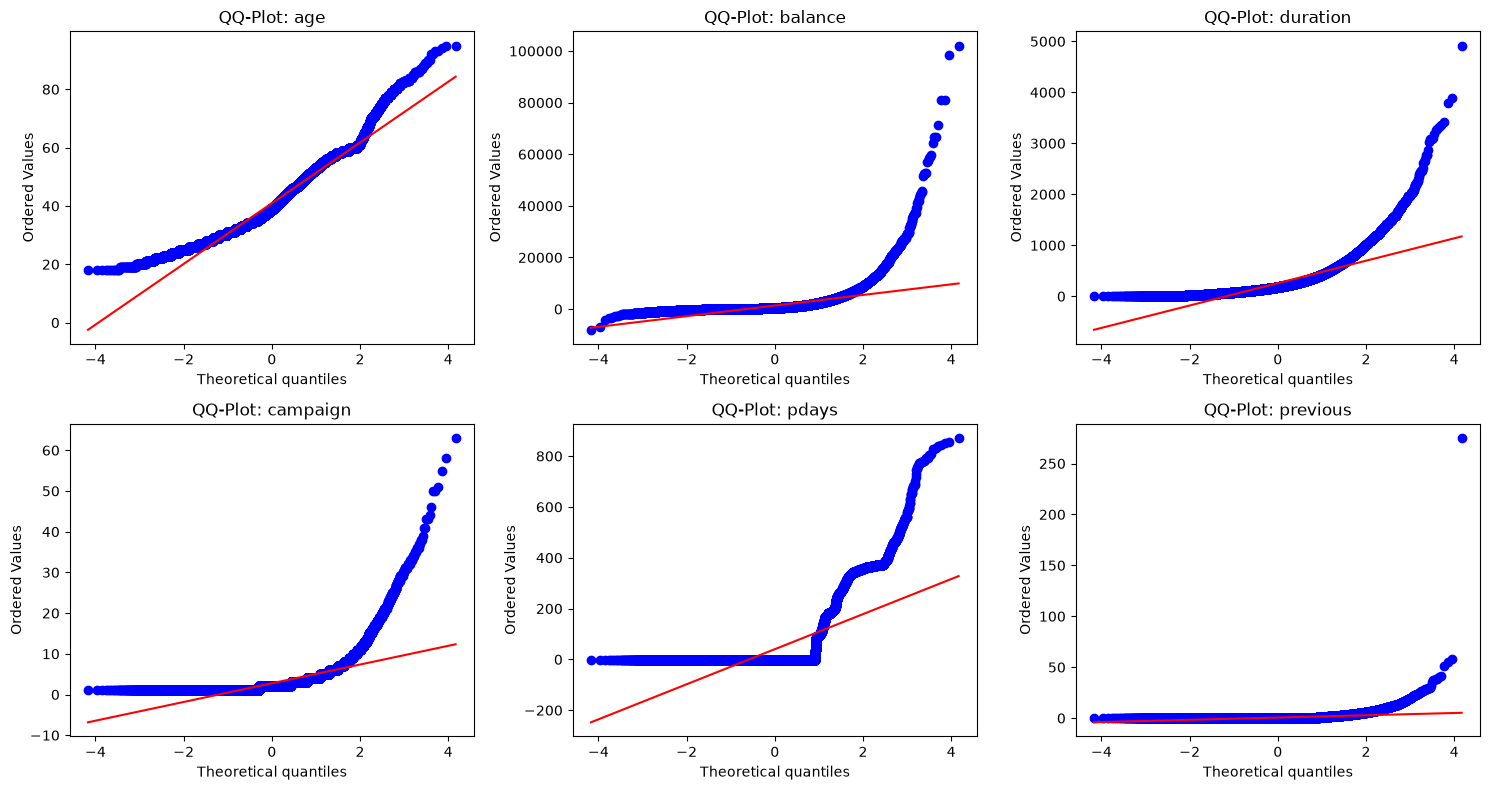

In [31]:
# Normality Test for Numerical Variables
from scipy.stats import shapiro
import scipy.stats as stats
import matplotlib.pyplot as plt

numeric_cols_to_test = ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']

for col in numeric_cols_to_test:
    sample = df[col].sample(5000, random_state=42)
    stat, p = shapiro(sample)
    print(f"{col}: Shapiro-Wilk stat={stat:.4f}, p-value={p:.6f}")

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for i, col in enumerate(numeric_cols_to_test):
    stats.probplot(df[col], dist="norm", plot=axes[i])
    axes[i].set_title(f'QQ-Plot: {col}')
plt.tight_layout()
plt.show()

In [32]:
# Homogeneity of Variance Test (Levene's Test) and Mann-Whitney U Test
from scipy.stats import levene, mannwhitneyu

mw_results = []

for col in numeric_cols_to_test:
    yes_group = df[df['y'] == 'yes'][col]
    no_group = df[df['y'] == 'no'][col]
    
    lev_stat, lev_p = levene(yes_group, no_group)
    u_stat, u_p = mannwhitneyu(yes_group, no_group, alternative='two-sided')
    
    mw_results.append({'feature': col, 'levene_p': lev_p, 'mannwhitney_p': u_p})

mw_df = pd.DataFrame(mw_results)
print(mw_df)

    feature       levene_p  mannwhitney_p
0       age  2.420858e-133   6.281791e-02
1   balance   5.020129e-15  6.593846e-101
2  duration   0.000000e+00   0.000000e+00
3  campaign   8.220318e-33   1.948490e-71
4     pdays  3.790553e-108  2.484118e-235
5  previous   7.801830e-88  3.491824e-283


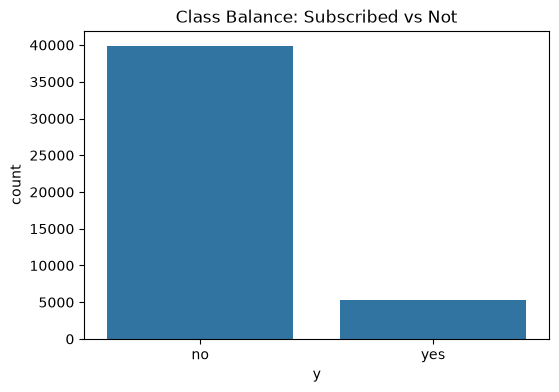

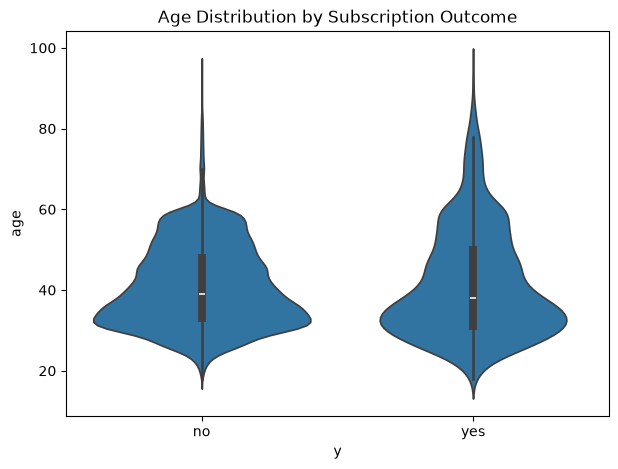

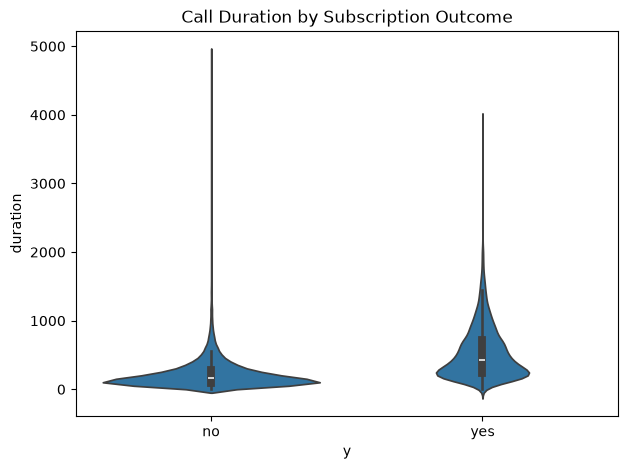

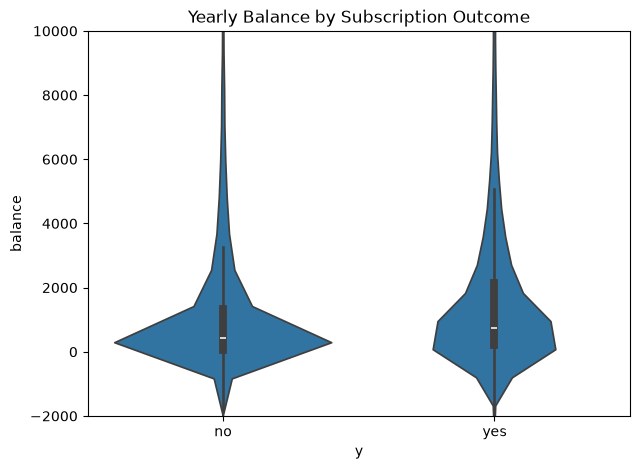

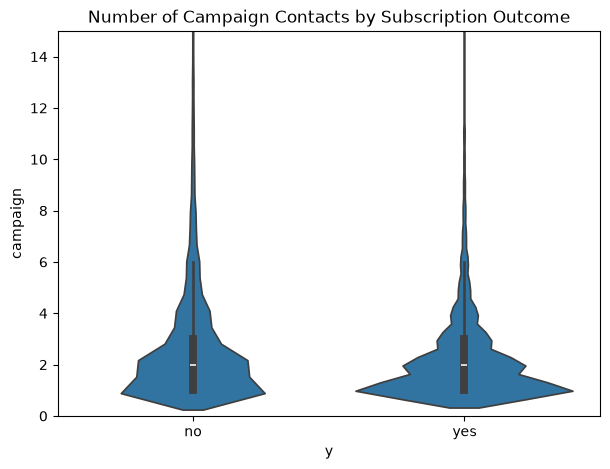

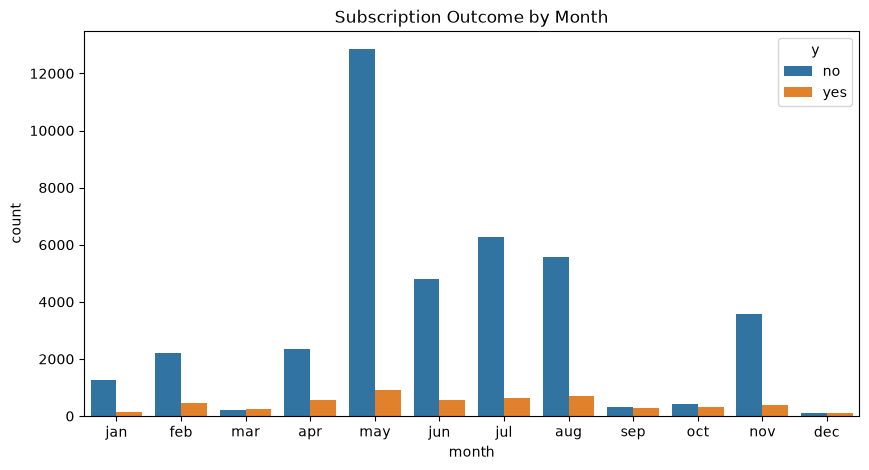

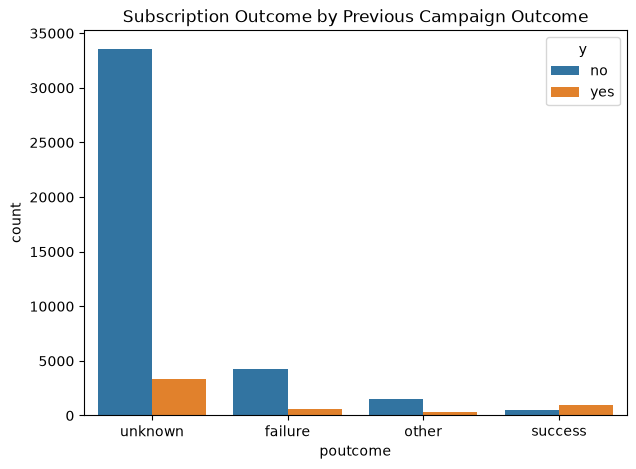

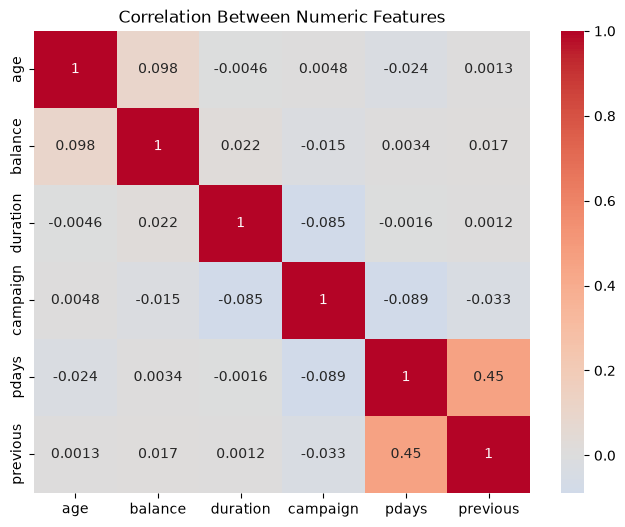

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Target class balance
plt.figure(figsize=(6,4))
sns.countplot(x='y', data=df)
plt.title('Class Balance: Subscribed vs Not')
plt.show()

# 2. Age vs y — violin plot (to actually SEE the U-shape we inferred)
plt.figure(figsize=(7,5))
sns.violinplot(x='y', y='age', data=df)
plt.title('Age Distribution by Subscription Outcome')
plt.show()

# 3. Duration vs y — violin plot (the leakage feature, worth seeing visually)
plt.figure(figsize=(7,5))
sns.violinplot(x='y', y='duration', data=df)
plt.title('Call Duration by Subscription Outcome')
plt.show()

# 4. Balance vs y
plt.figure(figsize=(7,5))
sns.violinplot(x='y', y='balance', data=df)
plt.ylim(-2000, 10000)  # zoom in, since balance has extreme outliers
plt.title('Yearly Balance by Subscription Outcome')
plt.show()

# 5. Campaign (number of contacts) vs y
plt.figure(figsize=(7,5))
sns.violinplot(x='y', y='campaign', data=df)
plt.ylim(0, 15)
plt.title('Number of Campaign Contacts by Subscription Outcome')
plt.show()

# 6. Categorical: subscription rate by month
plt.figure(figsize=(10,5))
month_order = ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
sns.countplot(x='month', hue='y', data=df, order=month_order)
plt.title('Subscription Outcome by Month')
plt.show()

# 7. Categorical: subscription rate by poutcome
plt.figure(figsize=(7,5))
sns.countplot(x='poutcome', hue='y', data=df)
plt.title('Subscription Outcome by Previous Campaign Outcome')
plt.show()

# 8. Correlation heatmap (numeric features only)
plt.figure(figsize=(8,6))
numeric_cols = ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Between Numeric Features')
plt.show()

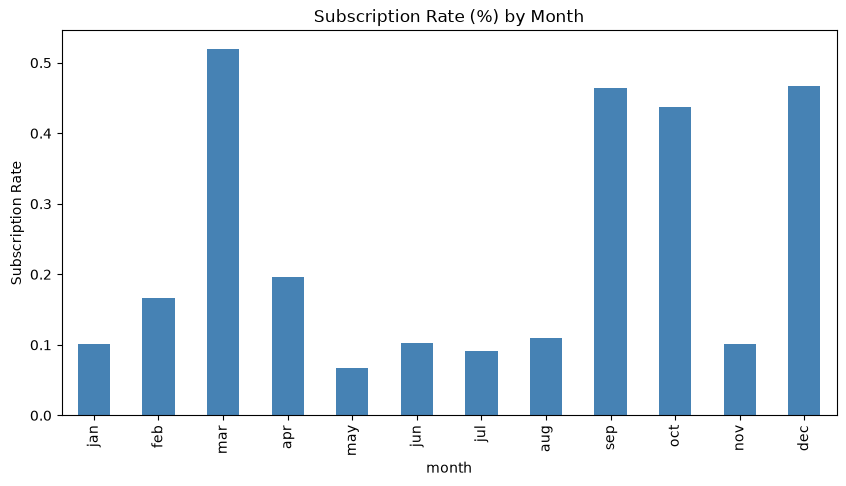

In [34]:
month_order = ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
month_rate = df.groupby('month')['y'].apply(lambda x: (x=='yes').mean()).reindex(month_order)

plt.figure(figsize=(10,5))
month_rate.plot(kind='bar', color='steelblue')
plt.title('Subscription Rate (%) by Month')
plt.ylabel('Subscription Rate')
plt.show()

In [35]:
#feature engineering
import numpy as np
from scipy.stats import chi2_contingency

# --- 1. was_previously_contacted flag ---
# Confirmed sentinel is -1 for bank-full.csv (matches previous==0 count exactly)
df['was_previously_contacted'] = (df['pdays'] != -1).astype(int)

# --- 2. age_group buckets (vectorized) ---
df['age_group'] = pd.cut(
    df['age'], 
    bins=[0, 30, 45, 60, np.inf], 
    labels=['young', 'middle', 'senior', 'elderly']
).astype(str)

# --- 3. campaign_intensity buckets (vectorized) ---
df['campaign_intensity'] = pd.cut(
    df['campaign'], 
    bins=[0, 2, 5, np.inf], 
    labels=['low', 'medium', 'high']
).astype(str)

# --- 4. contact_month_quarter ---
month_to_quarter = {
    'jan': 'Q1', 'feb': 'Q1', 'mar': 'Q1',
    'apr': 'Q2', 'may': 'Q2', 'jun': 'Q2',
    'jul': 'Q3', 'aug': 'Q3', 'sep': 'Q3',
    'oct': 'Q4', 'nov': 'Q4', 'dec': 'Q4'
}
df['contact_month_quarter'] = df['month'].map(month_to_quarter)

# --- 5. has_any_loan ---
df['has_any_loan'] = ((df['housing'] == 'yes') | (df['loan'] == 'yes')).astype(int)

# --- 6. demographic_profile (with cardinality protection) ---
raw_profile = df['age_group'] + '_' + df['job']
frequent_profiles = raw_profile.value_counts(normalize=True)
frequent_profiles = frequent_profiles[frequent_profiles >= 0.01].index
df['demographic_profile'] = raw_profile.where(raw_profile.isin(frequent_profiles), 'other_profile')

# Verification
print("Dataset New Shape:", df.shape)
print("Protected unique demographic categories:", df['demographic_profile'].nunique())

contingency = pd.crosstab(df['demographic_profile'], df['y'])
_, p_value, _, _ = chi2_contingency(contingency)
print(f"demographic_profile Chi-Square p-value: {p_value:.6f}")

Dataset New Shape: (45211, 23)
Protected unique demographic categories: 25
demographic_profile Chi-Square p-value: 0.000000


In [36]:
#train-test split
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=['y'])
y_target = df['y']

# Stratified 80/20 split — preserves the 88.3%/11.7% class ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y_target,
    test_size=0.2,
    stratify=y_target,
    random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

# Confirm the split preserved class balance
print("\nTrain class balance:")
print(y_train.value_counts(normalize=True) * 100)
print("\nTest class balance:")
print(y_test.value_counts(normalize=True) * 100)

Train shape: (36168, 22)
Test shape: (9043, 22)

Train class balance:
y
no     88.301814
yes    11.698186
Name: proportion, dtype: float64

Test class balance:
y
no     88.300343
yes    11.699657
Name: proportion, dtype: float64


In [37]:
# Two versions: with duration (benchmark) and without (realistic, deployable)
X_train_with_duration = X_train.copy()
X_test_with_duration = X_test.copy()

X_train_no_duration = X_train.drop(columns=['duration'])
X_test_no_duration = X_test.drop(columns=['duration'])

print("With duration:", X_train_with_duration.shape)
print("Without duration:", X_train_no_duration.shape)

With duration: (36168, 22)
Without duration: (36168, 21)


In [38]:
#encoding csategorical variables
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# --- Ordinal encoding for education (has a real order) ---
education_order = [['primary', 'secondary', 'tertiary', 'unknown']]  
# putting 'unknown' last, treated as its own rank rather than guessing its true position

ordinal_encoder = OrdinalEncoder(categories=education_order)

X_train['education_encoded'] = ordinal_encoder.fit_transform(X_train[['education']])
X_test['education_encoded'] = ordinal_encoder.transform(X_test[['education']])

# --- One-hot encoding for nominal categoricals ---
nominal_cols = ['job', 'marital', 'default', 'housing', 'loan', 'contact', 
                 'month', 'poutcome', 'age_group', 'campaign_intensity', 
                 'contact_month_quarter', 'demographic_profile']

onehot_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Fit on train only
onehot_encoder.fit(X_train[nominal_cols])

# Transform both
X_train_onehot = pd.DataFrame(
    onehot_encoder.transform(X_train[nominal_cols]),
    columns=onehot_encoder.get_feature_names_out(nominal_cols),
    index=X_train.index
)

X_test_onehot = pd.DataFrame(
    onehot_encoder.transform(X_test[nominal_cols]),
    columns=onehot_encoder.get_feature_names_out(nominal_cols),
    index=X_test.index
)

# --- Combine everything: numeric + education_encoded + one-hot columns ---
numeric_cols_final = ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous', 
                       'was_previously_contacted', 'has_any_loan', 'education_encoded']

X_train_encoded = pd.concat([X_train[numeric_cols_final].reset_index(drop=True), 
                               X_train_onehot.reset_index(drop=True)], axis=1)

X_test_encoded = pd.concat([X_test[numeric_cols_final].reset_index(drop=True), 
                              X_test_onehot.reset_index(drop=True)], axis=1)

print("Encoded train shape:", X_train_encoded.shape)
print("Encoded test shape:", X_test_encoded.shape)
X_train_encoded.head()

Encoded train shape: (36168, 85)
Encoded test shape: (9043, 85)


,age,balance,duration,campaign,pdays,previous,was_previously_contacted,has_any_loan,education_encoded,job_admin.,...,demographic_profile_senior_management,demographic_profile_senior_retired,demographic_profile_senior_services,demographic_profile_senior_technician,demographic_profile_young_admin.,demographic_profile_young_blue-collar,demographic_profile_young_management,demographic_profile_young_services,demographic_profile_young_student,demographic_profile_young_technician
0,36,861,140,2,-1,0,0,0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,24,4126,907,4,185,7,1,0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,44,244,1735,4,-1,0,0,1,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,48,0,35,11,-1,0,0,0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,38,257,57,10,-1,0,0,0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [39]:
#VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

# VIF requires no missing values and works on numeric arrays
# Using .values to avoid feature name warnings
X_vif = X_train_encoded.copy()

vif_data = pd.DataFrame()
vif_data['feature'] = X_vif.columns
vif_data['VIF'] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]

vif_data = vif_data.sort_values('VIF', ascending=False)
print(vif_data.head(20))

                                    feature           VIF
65    demographic_profile_middle_management  3.117428e+08
24                               default_no  2.134337e+08
25                              default_yes  2.134337e+08
20                              job_unknown  1.256371e+08
43                                month_oct  1.075149e+08
63  demographic_profile_middle_entrepreneur  7.802456e+07
81     demographic_profile_young_management  7.019838e+07
82       demographic_profile_young_services  5.868759e+07
67      demographic_profile_middle_services  5.728078e+07
83        demographic_profile_young_student  5.155244e+07
79         demographic_profile_young_admin.  5.103991e+07
11                         job_entrepreneur  4.640287e+07
60      demographic_profile_elderly_retired  4.368024e+07
74     demographic_profile_senior_housemaid  4.165197e+07
44                                month_sep  3.752911e+07
71        demographic_profile_senior_admin.  3.610961e+07
69    demograp

In [40]:
onehot_encoder = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)

onehot_encoder.fit(X_train[nominal_cols])

X_train_onehot = pd.DataFrame(
    onehot_encoder.transform(X_train[nominal_cols]),
    columns=onehot_encoder.get_feature_names_out(nominal_cols),
    index=X_train.index
)

X_test_onehot = pd.DataFrame(
    onehot_encoder.transform(X_test[nominal_cols]),
    columns=onehot_encoder.get_feature_names_out(nominal_cols),
    index=X_test.index
)

X_train_encoded = pd.concat([X_train[numeric_cols_final].reset_index(drop=True), 
                               X_train_onehot.reset_index(drop=True)], axis=1)

X_test_encoded = pd.concat([X_test[numeric_cols_final].reset_index(drop=True), 
                              X_test_onehot.reset_index(drop=True)], axis=1)

print("Re-encoded train shape:", X_train_encoded.shape)

Re-encoded train shape: (36168, 73)


In [41]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = X_train_encoded.copy()

vif_data = pd.DataFrame()
vif_data['feature'] = X_vif.columns
vif_data['VIF'] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]

vif_data = vif_data.sort_values('VIF', ascending=False)
print(vif_data.head(20))

                                   feature           VIF
28                               month_dec  1.000800e+15
30                               month_jan  7.932916e+07
33                               month_mar  4.543098e+07
48                contact_month_quarter_Q4  3.473627e+07
36                               month_oct  8.677090e+06
35                               month_nov  5.053596e+06
29                               month_feb  4.351746e+06
47                contact_month_quarter_Q3  3.132740e+06
37                               month_sep  3.021238e+06
27                               month_aug  1.978340e+06
46                contact_month_quarter_Q2  1.377651e+06
31                               month_jul  1.298722e+06
15                            job_services  1.659655e+03
55     demographic_profile_middle_services  1.092929e+03
6                 was_previously_contacted  1.088083e+03
40                        poutcome_unknown  1.082156e+03
50  demographic_profile_middle_

In [42]:
# Drop the redundant contact_month_quarter columns
quarter_cols = [col for col in X_train_encoded.columns if col.startswith('contact_month_quarter_')]
X_train_encoded = X_train_encoded.drop(columns=quarter_cols)
X_test_encoded = X_test_encoded.drop(columns=quarter_cols)

print("New shape after dropping redundant quarter columns:", X_train_encoded.shape)

# Re-run VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data['feature'] = X_train_encoded.columns
vif_data['VIF'] = [variance_inflation_factor(X_train_encoded.values, i) for i in range(X_train_encoded.shape[1])]

vif_data = vif_data.sort_values('VIF', ascending=False)
print(vif_data.head(20))

New shape after dropping redundant quarter columns: (36168, 70)
                                   feature          VIF
15                            job_services  1673.604122
52     demographic_profile_middle_services  1093.405345
6                 was_previously_contacted  1088.149701
40                        poutcome_unknown  1082.448364
47  demographic_profile_middle_blue-collar   647.298420
9                          job_blue-collar   575.582587
53   demographic_profile_middle_technician   535.034990
50   demographic_profile_middle_management   516.677896
62     demographic_profile_senior_services   470.078026
17                          job_technician   455.409821
67      demographic_profile_young_services   385.956727
46       demographic_profile_middle_admin.   368.740819
12                          job_management   367.117299
41                        age_group_middle   264.783691
57  demographic_profile_senior_blue-collar   260.797790
60   demographic_profile_senior_manageme

In [43]:
# Drop job and age_group individually, keep only demographic_profile (their interaction)
job_cols = [col for col in X_train_encoded.columns if col.startswith('job_')]
age_group_cols = [col for col in X_train_encoded.columns if col.startswith('age_group_')]

X_train_encoded = X_train_encoded.drop(columns=job_cols + age_group_cols)
X_test_encoded = X_test_encoded.drop(columns=job_cols + age_group_cols)

print("New shape:", X_train_encoded.shape)

vif_data = pd.DataFrame()
vif_data['feature'] = X_train_encoded.columns
vif_data['VIF'] = [variance_inflation_factor(X_train_encoded.values, i) for i in range(X_train_encoded.shape[1])]

vif_data = vif_data.sort_values('VIF', ascending=False)
print(vif_data.head(20))

New shape: (36168, 56)
                                   feature          VIF
6                 was_previously_contacted  1088.133698
29                        poutcome_unknown  1082.435477
33  demographic_profile_middle_blue-collar    11.695925
36   demographic_profile_middle_management    11.651255
39   demographic_profile_middle_technician    10.022067
7                             has_any_loan     7.591701
30                  campaign_intensity_low     7.420081
12                             housing_yes     6.883320
32       demographic_profile_middle_admin.     6.819711
38     demographic_profile_middle_services     5.851163
51   demographic_profile_young_blue-collar     5.104298
43  demographic_profile_senior_blue-collar     5.046832
41       demographic_profile_other_profile     4.957545
0                                      age     4.841682
46   demographic_profile_senior_management     4.826682
4                                    pdays     4.737422
31               campaign

In [44]:
X_train_encoded = X_train_encoded.drop(columns=['was_previously_contacted'])
X_test_encoded = X_test_encoded.drop(columns=['was_previously_contacted'])

print("New shape:", X_train_encoded.shape)

vif_data = pd.DataFrame()
vif_data['feature'] = X_train_encoded.columns
vif_data['VIF'] = [variance_inflation_factor(X_train_encoded.values, i) for i in range(X_train_encoded.shape[1])]

vif_data = vif_data.sort_values('VIF', ascending=False)
print(vif_data.head(15))

New shape: (36168, 55)
                                   feature        VIF
32  demographic_profile_middle_blue-collar  11.693845
35   demographic_profile_middle_management  11.650245
38   demographic_profile_middle_technician  10.020341
6                             has_any_loan   7.591025
29                  campaign_intensity_low   7.420066
11                             housing_yes   6.882846
31       demographic_profile_middle_admin.   6.818633
28                        poutcome_unknown   6.236720
37     demographic_profile_middle_services   5.850282
50   demographic_profile_young_blue-collar   5.103588
42  demographic_profile_senior_blue-collar   5.045969
40       demographic_profile_other_profile   4.956589
0                                      age   4.841598
45   demographic_profile_senior_management   4.825894
30               campaign_intensity_medium   4.734983


In [45]:
X_train_no_duration = X_train_encoded.drop(columns=['duration'])
X_test_no_duration = X_test_encoded.drop(columns=['duration'])

print("With duration:", X_train_encoded.shape)
print("Without duration:", X_train_no_duration.shape)

With duration: (36168, 55)
Without duration: (36168, 54)


In [46]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
log_reg.fit(X_train_no_duration, y_train)

# Predictions
y_pred = log_reg.predict(X_test_no_duration)
y_pred_proba = log_reg.predict_proba(X_test_no_duration)[:, 1]

# Quick check
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, pos_label='yes'))
print("Recall:", recall_score(y_test, y_pred, pos_label='yes'))
print("F1:", f1_score(y_test, y_pred, pos_label='yes'))
print("ROC-AUC:", roc_auc_score(y_test.map({'no':0,'yes':1}), y_pred_proba))

Accuracy: 0.7603671348003981
Precision: 0.2750507099391481
Recall: 0.6408317580340265
F1: 0.3848992336077207
ROC-AUC: 0.7728231573141039


In [47]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(class_weight='balanced', max_depth=8, random_state=42)
dt.fit(X_train_no_duration, y_train)

y_pred = dt.predict(X_test_no_duration)
y_pred_proba = dt.predict_proba(X_test_no_duration)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, pos_label='yes'))
print("Recall:", recall_score(y_test, y_pred, pos_label='yes'))
print("F1:", f1_score(y_test, y_pred, pos_label='yes'))
print("ROC-AUC:", roc_auc_score(y_test.map({'no':0,'yes':1}), y_pred_proba))

Accuracy: 0.8238416454716355
Precision: 0.34255444379046496
Recall: 0.5500945179584121
F1: 0.42219804134929273
ROC-AUC: 0.7533869625585782


In [48]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(class_weight='balanced', n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train_no_duration, y_train)

y_pred = rf.predict(X_test_no_duration)
y_pred_proba = rf.predict_proba(X_test_no_duration)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, pos_label='yes'))
print("Recall:", recall_score(y_test, y_pred, pos_label='yes'))
print("F1:", f1_score(y_test, y_pred, pos_label='yes'))
print("ROC-AUC:", roc_auc_score(y_test.map({'no':0,'yes':1}), y_pred_proba))

Accuracy: 0.7989605219506801
Precision: 0.314453125
Recall: 0.6086956521739131
F1: 0.41468126207340633
ROC-AUC: 0.7847890598274411


In [49]:
from sklearn.svm import SVC

svm = SVC(class_weight='balanced', probability=True, random_state=42)
svm.fit(X_train_no_duration, y_train)

y_pred = svm.predict(X_test_no_duration)
y_pred_proba = svm.predict_proba(X_test_no_duration)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, pos_label='yes'))
print("Recall:", recall_score(y_test, y_pred, pos_label='yes'))
print("F1:", f1_score(y_test, y_pred, pos_label='yes'))
print("ROC-AUC:", roc_auc_score(y_test.map({'no':0,'yes':1}), y_pred_proba))

Accuracy: 0.6433705628663055
Precision: 0.1652764905776954
Recall: 0.505671077504726
F1: 0.24912689173457508
ROC-AUC: 0.6229613535776556


In [50]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train_no_duration_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_no_duration),
    columns=X_train_no_duration.columns,
    index=X_train_no_duration.index
)

X_test_no_duration_scaled = pd.DataFrame(
    scaler.transform(X_test_no_duration),
    columns=X_test_no_duration.columns,
    index=X_test_no_duration.index
)

# Re-run SVM on scaled data
from sklearn.svm import SVC

svm = SVC(class_weight='balanced', probability=True, random_state=42)
svm.fit(X_train_no_duration_scaled, y_train)

y_pred = svm.predict(X_test_no_duration_scaled)
y_pred_proba = svm.predict_proba(X_test_no_duration_scaled)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, pos_label='yes'))
print("Recall:", recall_score(y_test, y_pred, pos_label='yes'))
print("F1:", f1_score(y_test, y_pred, pos_label='yes'))
print("ROC-AUC:", roc_auc_score(y_test.map({'no':0,'yes':1}), y_pred_proba))

Accuracy: 0.8133362822072321
Precision: 0.33368532206969376
Recall: 0.5973534971644613
F1: 0.4281842818428184
ROC-AUC: 0.7671481736194874


In [51]:
from xgboost import XGBClassifier

# Calculate scale_pos_weight = (count of negative class) / (count of positive class)
neg_count = (y_train == 'no').sum()
pos_count = (y_train == 'yes').sum()
scale_pos_weight = neg_count / pos_count
print("scale_pos_weight:", scale_pos_weight)

# XGBoost needs numeric target, not strings
y_train_numeric = y_train.map({'no': 0, 'yes': 1})
y_test_numeric = y_test.map({'no': 0, 'yes': 1})

xgb = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss'
)
xgb.fit(X_train_no_duration, y_train_numeric)

y_pred = xgb.predict(X_test_no_duration)
y_pred_proba = xgb.predict_proba(X_test_no_duration)[:, 1]

print("Accuracy:", accuracy_score(y_test_numeric, y_pred))
print("Precision:", precision_score(y_test_numeric, y_pred))
print("Recall:", recall_score(y_test_numeric, y_pred))
print("F1:", f1_score(y_test_numeric, y_pred))
print("ROC-AUC:", roc_auc_score(y_test_numeric, y_pred_proba))

scale_pos_weight: 7.548333727251241
Accuracy: 0.8103505473847175
Precision: 0.3304078471863707
Recall: 0.6049149338374291
F1: 0.4273789649415693
ROC-AUC: 0.7760807421287315


In [52]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train_no_duration, y_train)

y_pred = nb.predict(X_test_no_duration)
y_pred_proba = nb.predict_proba(X_test_no_duration)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, pos_label='yes'))
print("Recall:", recall_score(y_test, y_pred, pos_label='yes'))
print("F1:", f1_score(y_test, y_pred, pos_label='yes'))
print("ROC-AUC:", roc_auc_score(y_test.map({'no':0,'yes':1}), y_pred_proba))


Accuracy: 0.8404290611522724
Precision: 0.3564504101416853
Recall: 0.45179584120982985
F1: 0.3984993747394748
ROC-AUC: 0.7489136649175616


In [53]:
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout
from keras.optimizers import Adam

# Build the ANN
ann = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_no_duration_scaled.shape[1],)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

ann.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

# Class weights for imbalance
class_weight_dict = {0: 1.0, 1: scale_pos_weight}  # reusing the ratio we computed for XGBoost

# Early stopping to prevent overfitting
from keras.callbacks import EarlyStopping
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = ann.fit(
    X_train_no_duration_scaled, y_train_numeric,
    validation_split=0.2,
    epochs=50,
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=1
)

# Predictions
y_pred_proba_ann = ann.predict(X_test_no_duration_scaled).flatten()
y_pred_ann = (y_pred_proba_ann >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test_numeric, y_pred_ann))
print("Precision:", precision_score(y_test_numeric, y_pred_ann))
print("Recall:", recall_score(y_test_numeric, y_pred_ann))
print("F1:", f1_score(y_test_numeric, y_pred_ann))
print("ROC-AUC:", roc_auc_score(y_test_numeric, y_pred_proba_ann))

Epoch 1/50
453/453 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6907 - loss: 1.0975 - val_accuracy: 0.7421 - val_loss: 0.5907
Epoch 2/50
453/453 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7549 - loss: 1.0274 - val_accuracy: 0.7943 - val_loss: 0.5628
Epoch 3/50
453/453 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7709 - loss: 1.0183 - val_accuracy: 0.8232 - val_loss: 0.5433
Epoch 4/50
453/453 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7790 - loss: 1.0056 - val_accuracy: 0.8094 - val_loss: 0.5601
Epoch 5/50
453/453 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7884 - loss: 0.9989 - val_accuracy: 0.8041 - val_loss: 0.5378
Epoch 6/50
453/453 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7862 - loss: 0.9941 - val_accuracy: 0.8054 - val_loss: 0.5426
Epoch 7/50
453/453 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7914 - loss: 0.9907 - val_accuracy: 0.7943 - val_loss: 0.5610
Epoch 8/50
453/453 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7917 - loss: 0.9857 - val_accuracy: 0.

In [54]:
X_train_with_duration_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_encoded),
    columns=X_train_encoded.columns,
    index=X_train_encoded.index
)

X_test_with_duration_scaled = pd.DataFrame(
    scaler.transform(X_test_encoded),
    columns=X_test_encoded.columns,
    index=X_test_encoded.index
)

In [55]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

results_with_duration = {}

# Logistic Regression
lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr.fit(X_train_encoded, y_train)
pred = lr.predict(X_test_encoded)
proba = lr.predict_proba(X_test_encoded)[:, 1]
results_with_duration['Logistic Regression'] = {
    'Accuracy': accuracy_score(y_test, pred),
    'Precision': precision_score(y_test, pred, pos_label='yes'),
    'Recall': recall_score(y_test, pred, pos_label='yes'),
    'F1': f1_score(y_test, pred, pos_label='yes'),
    'ROC-AUC': roc_auc_score(y_test.map({'no':0,'yes':1}), proba)
}

# Decision Tree
dt = DecisionTreeClassifier(class_weight='balanced', max_depth=8, random_state=42)
dt.fit(X_train_encoded, y_train)
pred = dt.predict(X_test_encoded)
proba = dt.predict_proba(X_test_encoded)[:, 1]
results_with_duration['Decision Tree'] = {
    'Accuracy': accuracy_score(y_test, pred),
    'Precision': precision_score(y_test, pred, pos_label='yes'),
    'Recall': recall_score(y_test, pred, pos_label='yes'),
    'F1': f1_score(y_test, pred, pos_label='yes'),
    'ROC-AUC': roc_auc_score(y_test.map({'no':0,'yes':1}), proba)
}

# Random Forest
rf = RandomForestClassifier(class_weight='balanced', n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train_encoded, y_train)
pred = rf.predict(X_test_encoded)
proba = rf.predict_proba(X_test_encoded)[:, 1]
results_with_duration['Random Forest'] = {
    'Accuracy': accuracy_score(y_test, pred),
    'Precision': precision_score(y_test, pred, pos_label='yes'),
    'Recall': recall_score(y_test, pred, pos_label='yes'),
    'F1': f1_score(y_test, pred, pos_label='yes'),
    'ROC-AUC': roc_auc_score(y_test.map({'no':0,'yes':1}), proba)
}

# SVM (scaled)
svm = SVC(class_weight='balanced', probability=True, random_state=42)
svm.fit(X_train_with_duration_scaled, y_train)
pred = svm.predict(X_test_with_duration_scaled)
proba = svm.predict_proba(X_test_with_duration_scaled)[:, 1]
results_with_duration['SVM'] = {
    'Accuracy': accuracy_score(y_test, pred),
    'Precision': precision_score(y_test, pred, pos_label='yes'),
    'Recall': recall_score(y_test, pred, pos_label='yes'),
    'F1': f1_score(y_test, pred, pos_label='yes'),
    'ROC-AUC': roc_auc_score(y_test.map({'no':0,'yes':1}), proba)
}

# XGBoost
xgb2 = XGBClassifier(scale_pos_weight=scale_pos_weight, n_estimators=200, max_depth=6, learning_rate=0.1, random_state=42, eval_metric='logloss')
xgb2.fit(X_train_encoded, y_train_numeric)
pred = xgb2.predict(X_test_encoded)
proba = xgb2.predict_proba(X_test_encoded)[:, 1]
results_with_duration['XGBoost'] = {
    'Accuracy': accuracy_score(y_test_numeric, pred),
    'Precision': precision_score(y_test_numeric, pred),
    'Recall': recall_score(y_test_numeric, pred),
    'F1': f1_score(y_test_numeric, pred),
    'ROC-AUC': roc_auc_score(y_test_numeric, proba)
}

# Naive Bayes
nb = GaussianNB()
nb.fit(X_train_encoded, y_train)
pred = nb.predict(X_test_encoded)
proba = nb.predict_proba(X_test_encoded)[:, 1]
results_with_duration['Naive Bayes'] = {
    'Accuracy': accuracy_score(y_test, pred),
    'Precision': precision_score(y_test, pred, pos_label='yes'),
    'Recall': recall_score(y_test, pred, pos_label='yes'),
    'F1': f1_score(y_test, pred, pos_label='yes'),
    'ROC-AUC': roc_auc_score(y_test.map({'no':0,'yes':1}), proba)
}

# Display as a table
results_df = pd.DataFrame(results_with_duration).T
print(results_df)

                     Accuracy  Precision    Recall        F1   ROC-AUC
Logistic Regression  0.841093   0.411075  0.827977  0.549389  0.907838
Decision Tree        0.832688   0.397198  0.830813  0.537450  0.879917
Random Forest        0.829481   0.396226  0.873346  0.545133  0.915688
SVM                  0.845848   0.419463  0.827032  0.556616  0.910841
XGBoost              0.854805   0.437346  0.841210  0.575493  0.923201
Naive Bayes          0.853699   0.403776  0.525520  0.456674  0.819045


In [56]:
ann_wd = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_with_duration_scaled.shape[1],)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

ann_wd.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

history_wd = ann_wd.fit(
    X_train_with_duration_scaled, y_train_numeric,
    validation_split=0.2,
    epochs=50,
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=1
)

y_pred_proba_ann_wd = ann_wd.predict(X_test_with_duration_scaled).flatten()
y_pred_ann_wd = (y_pred_proba_ann_wd >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test_numeric, y_pred_ann_wd))
print("Precision:", precision_score(y_test_numeric, y_pred_ann_wd))
print("Recall:", recall_score(y_test_numeric, y_pred_ann_wd))
print("F1:", f1_score(y_test_numeric, y_pred_ann_wd))
print("ROC-AUC:", roc_auc_score(y_test_numeric, y_pred_proba_ann_wd))

Epoch 1/50
453/453 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6957 - loss: 1.0668 - val_accuracy: 0.6728 - val_loss: 0.6270
Epoch 2/50
453/453 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7675 - loss: 0.9104 - val_accuracy: 0.8243 - val_loss: 0.4522
Epoch 3/50
453/453 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8008 - loss: 0.8033 - val_accuracy: 0.8090 - val_loss: 0.4495
Epoch 4/50
453/453 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8139 - loss: 0.7302 - val_accuracy: 0.8037 - val_loss: 0.4371
Epoch 5/50
453/453 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8174 - loss: 0.6981 - val_accuracy: 0.8148 - val_loss: 0.4021
Epoch 6/50
453/453 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8180 - loss: 0.6756 - val_accuracy: 0.8416 - val_loss: 0.3431
Epoch 7/50
453/453 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8170 - loss: 0.6622 - val_accuracy: 0.8253 - val_loss: 0.3767
Epoch 8/50
453/453 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8209 - loss: 0.6494 - val_accuracy: 0.

In [57]:
# --- Consolidated no-duration model training with saved predictions ---

# Logistic Regression
log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
log_reg.fit(X_train_no_duration, y_train)
y_pred_lr = log_reg.predict(X_test_no_duration)
y_proba_lr = log_reg.predict_proba(X_test_no_duration)[:, 1]

# Decision Tree
dt = DecisionTreeClassifier(class_weight='balanced', max_depth=8, random_state=42)
dt.fit(X_train_no_duration, y_train)
y_pred_dt = dt.predict(X_test_no_duration)
y_proba_dt = dt.predict_proba(X_test_no_duration)[:, 1]

# Random Forest
rf = RandomForestClassifier(class_weight='balanced', n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train_no_duration, y_train)
y_pred_rf = rf.predict(X_test_no_duration)
y_proba_rf = rf.predict_proba(X_test_no_duration)[:, 1]

# SVM (scaled)
svm = SVC(class_weight='balanced', probability=True, random_state=42)
svm.fit(X_train_no_duration_scaled, y_train)
y_pred_svm = svm.predict(X_test_no_duration_scaled)
y_proba_svm = svm.predict_proba(X_test_no_duration_scaled)[:, 1]

# XGBoost
xgb_model = XGBClassifier(scale_pos_weight=scale_pos_weight, n_estimators=200, max_depth=6, 
                            learning_rate=0.1, random_state=42, eval_metric='logloss')
xgb_model.fit(X_train_no_duration, y_train_numeric)
y_pred_xgb = xgb_model.predict(X_test_no_duration)
y_proba_xgb = xgb_model.predict_proba(X_test_no_duration)[:, 1]

# Naive Bayes
nb = GaussianNB()
nb.fit(X_train_no_duration, y_train)
y_pred_nb = nb.predict(X_test_no_duration)
y_proba_nb = nb.predict_proba(X_test_no_duration)[:, 1]

print("All models re-trained and predictions saved.")
print("Variables: y_pred_lr, y_pred_dt, y_pred_rf, y_pred_svm, y_pred_xgb, y_pred_nb")
print("(each in string 'no'/'yes' form, EXCEPT y_pred_xgb which is 0/1)")

All models re-trained and predictions saved.
Variables: y_pred_lr, y_pred_dt, y_pred_rf, y_pred_svm, y_pred_xgb, y_pred_nb
(each in string 'no'/'yes' form, EXCEPT y_pred_xgb which is 0/1)


In [58]:
y_pred_lr_num = pd.Series(y_pred_lr).map({'no':0,'yes':1}).values
y_pred_dt_num = pd.Series(y_pred_dt).map({'no':0,'yes':1}).values
y_pred_rf_num = pd.Series(y_pred_rf).map({'no':0,'yes':1}).values
y_pred_svm_num = pd.Series(y_pred_svm).map({'no':0,'yes':1}).values
y_pred_nb_num = pd.Series(y_pred_nb).map({'no':0,'yes':1}).values
# y_pred_xgb is already 0/1

print("All predictions now in consistent 0/1 format")

All predictions now in consistent 0/1 format


In [59]:
import numpy as np
from sklearn.metrics import f1_score

def bootstrap_f1_ci(y_true, y_pred, n_bootstrap=1000):
    scores = []
    y_true_arr = np.array(y_true)
    y_pred_arr = np.array(y_pred)
    n = len(y_true_arr)
    
    for _ in range(n_bootstrap):
        indices = np.random.choice(n, n, replace=True)
        score = f1_score(y_true_arr[indices], y_pred_arr[indices])
        scores.append(score)
    
    return np.mean(scores), np.percentile(scores, 2.5), np.percentile(scores, 97.5)

y_test_num = y_test.map({'no':0,'yes':1}).values

models_preds = {
    'Logistic Regression': y_pred_lr_num,
    'Decision Tree': y_pred_dt_num,
    'Random Forest': y_pred_rf_num,
    'SVM': y_pred_svm_num,
    'XGBoost': y_pred_xgb,
    'Naive Bayes': y_pred_nb_num
}

print(f"{'Model':<25}{'F1 Mean':<12}{'95% CI'}")
for name, preds in models_preds.items():
    mean, lo, hi = bootstrap_f1_ci(y_test_num, preds)
    print(f"{name:<25}{mean:.3f}       ({lo:.3f} - {hi:.3f})")

Model                    F1 Mean     95% CI
Logistic Regression      0.385       (0.366 - 0.406)
Decision Tree            0.422       (0.400 - 0.445)
Random Forest            0.415       (0.393 - 0.436)
SVM                      0.429       (0.406 - 0.450)
XGBoost                  0.427       (0.407 - 0.450)
Naive Bayes              0.398       (0.373 - 0.421)


In [60]:
#McNemar's Test for Model Comparison
from statsmodels.stats.contingency_tables import mcnemar

def mcnemar_table(y_true, pred_a, pred_b):
    correct_a = (np.array(pred_a) == np.array(y_true))
    correct_b = (np.array(pred_b) == np.array(y_true))
    
    both_correct = np.sum(correct_a & correct_b)
    a_only = np.sum(correct_a & ~correct_b)
    b_only = np.sum(~correct_a & correct_b)
    both_wrong = np.sum(~correct_a & ~correct_b)
    
    return [[both_correct, a_only], [b_only, both_wrong]]

table = mcnemar_table(y_test_num, y_pred_svm_num, y_pred_xgb)
print("Contingency table:", table)

result = mcnemar(table, exact=False, correction=True)
print(f"\nMcNemar statistic: {result.statistic:.4f}")
print(f"p-value: {result.pvalue:.4f}")

Contingency table: [[np.int64(6892), np.int64(463)], [np.int64(436), np.int64(1252)]]

McNemar statistic: 0.7519
p-value: 0.3859


In [61]:
#Threshold Tuning 
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_test_num, y_proba_xgb)

# F1 at each threshold
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)

best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print(f"Best threshold (max F1): {best_threshold:.3f}")
print(f"At this threshold — Precision: {precisions[best_idx]:.3f}, Recall: {recalls[best_idx]:.3f}, F1: {f1_scores[best_idx]:.3f}")

# Compare to default 0.5 threshold
print(f"\nDefault 0.5 threshold — Precision: {precision_score(y_test_num, y_pred_xgb):.3f}, Recall: {recall_score(y_test_num, y_pred_xgb):.3f}, F1: {f1_score(y_test_num, y_pred_xgb):.3f}")

Best threshold (max F1): 0.664
At this threshold — Precision: 0.469, Recall: 0.466, F1: 0.467

Default 0.5 threshold — Precision: 0.330, Recall: 0.605, F1: 0.427


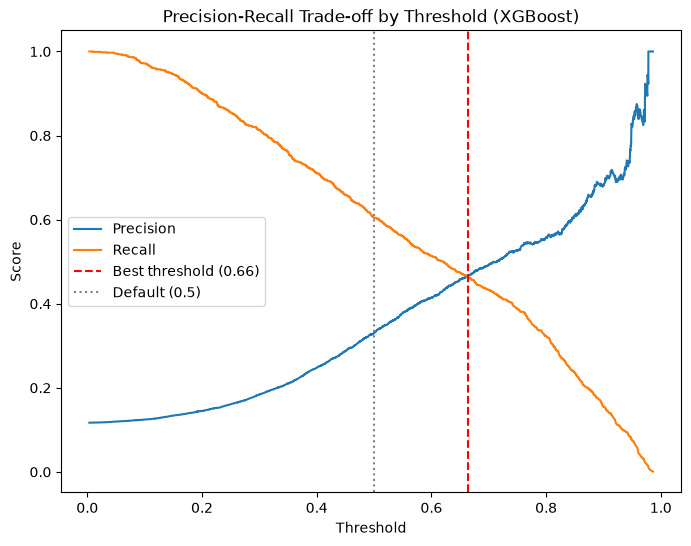

In [62]:
#visualization of Precision-Recall vs Threshold
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.plot(thresholds, precisions[:-1], label='Precision')
plt.plot(thresholds, recalls[:-1], label='Recall')
plt.axvline(best_threshold, color='red', linestyle='--', label=f'Best threshold ({best_threshold:.2f})')
plt.axvline(0.5, color='gray', linestyle=':', label='Default (0.5)')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision-Recall Trade-off by Threshold (XGBoost)')
plt.legend()
plt.show()

In [63]:
# Top 20% by predicted probability
threshold_top20 = np.percentile(y_proba_xgb, 80)  # 80th percentile = top 20%
y_pred_top20 = (y_proba_xgb >= threshold_top20).astype(int)

precision_top20 = precision_score(y_test_num, y_pred_top20)
recall_top20 = recall_score(y_test_num, y_pred_top20)

print(f"\nCalling only top 20% of leads (threshold={threshold_top20:.3f}):")
print(f"Precision: {precision_top20:.3f} (vs. base rate of {y_test_num.mean():.3f})")
print(f"Recall: {recall_top20:.3f} (i.e., we'd catch {recall_top20*100:.1f}% of all actual subscribers by calling just 20% of clients)")


Calling only top 20% of leads (threshold=0.516):
Precision: 0.346 (vs. base rate of 0.117)
Recall: 0.592 (i.e., we'd catch 59.2% of all actual subscribers by calling just 20% of clients)


In [64]:
#logistic regression coefficients and odds ratios
import numpy as np
import pandas as pd

coefficients = log_reg.coef_[0]
feature_names = X_train_no_duration.columns

odds_ratios = np.exp(coefficients)

odds_df = pd.DataFrame({
    'feature': feature_names,
    'coefficient': coefficients,
    'odds_ratio': odds_ratios
}).sort_values('odds_ratio', ascending=False)

print("Top 10 features INCREASING odds of subscription:")
print(odds_df.head(10))

print("\nTop 10 features DECREASING odds of subscription:")
print(odds_df.tail(10))

Top 10 features INCREASING odds of subscription:
                                  feature  coefficient  odds_ratio
26                       poutcome_success     2.148027    8.567937
20                              month_mar     0.832309    2.298620
23                              month_oct     0.814583    2.258234
24                              month_sep     0.612564    1.845157
52      demographic_profile_young_student     0.450874    1.569684
15                              month_dec     0.339231    1.403868
49  demographic_profile_young_blue-collar     0.321649    1.379401
19                              month_jun     0.302502    1.353241
48       demographic_profile_young_admin.     0.261520    1.298902
50   demographic_profile_young_management     0.247070    1.280268

Top 10 features DECREASING odds of subscription:
                                   feature  coefficient  odds_ratio
46     demographic_profile_senior_services    -0.248288    0.780135
44   demographic_profile_sen

Top 15 features by XGBoost gain importance:
             feature  importance
26  poutcome_success    0.263928
13   contact_unknown    0.091174
20         month_mar    0.061474
5       has_any_loan    0.058504
14         month_aug    0.037598
23         month_oct    0.032784
19         month_jun    0.027068
24         month_sep    0.023034
18         month_jul    0.021753
17         month_jan    0.020394
22         month_nov    0.018075
7    marital_married    0.016688
15         month_dec    0.016284
8     marital_single    0.010231
2           campaign    0.010094


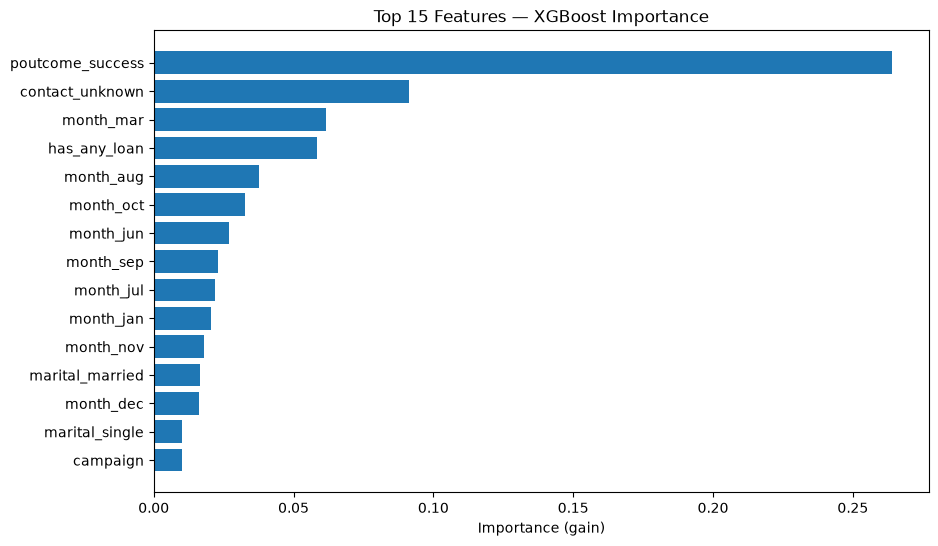

In [65]:
# XGBoost feature importance
importance_df = pd.DataFrame({
    'feature': X_train_no_duration.columns,
    'importance': xgb_model.feature_importances_
}).sort_values('importance', ascending=False)

print("Top 15 features by XGBoost gain importance:")
print(importance_df.head(15))

import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
plt.barh(importance_df.head(15)['feature'][::-1], importance_df.head(15)['importance'][::-1])
plt.title('Top 15 Features — XGBoost Importance')
plt.xlabel('Importance (gain)')
plt.show()

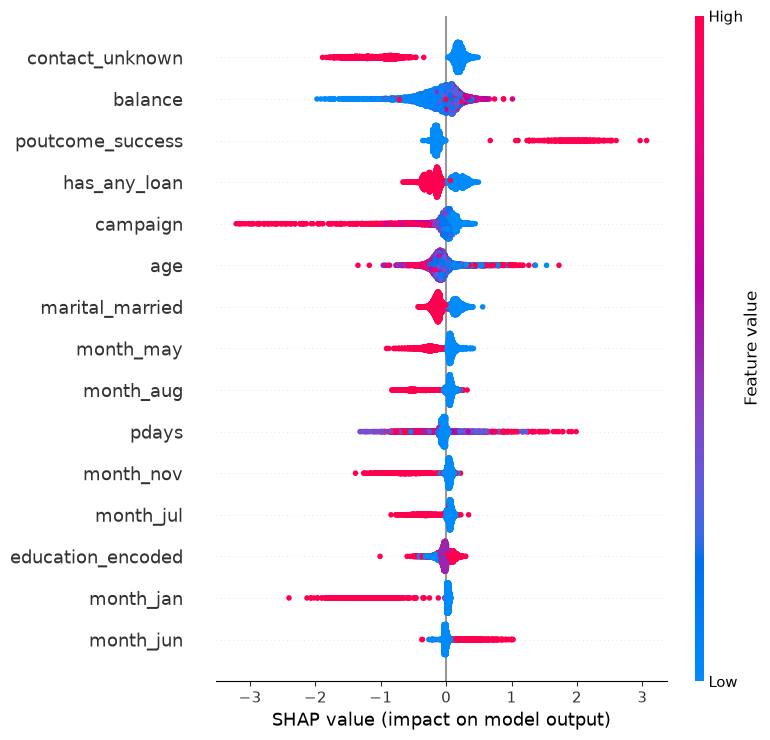

In [66]:
#SHAP values for XGBoost
import shap

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_no_duration)

# Summary plot: shows both magnitude AND direction (red=high value pushes toward yes, blue=low value)
shap.summary_plot(shap_values, X_test_no_duration, max_display=15)

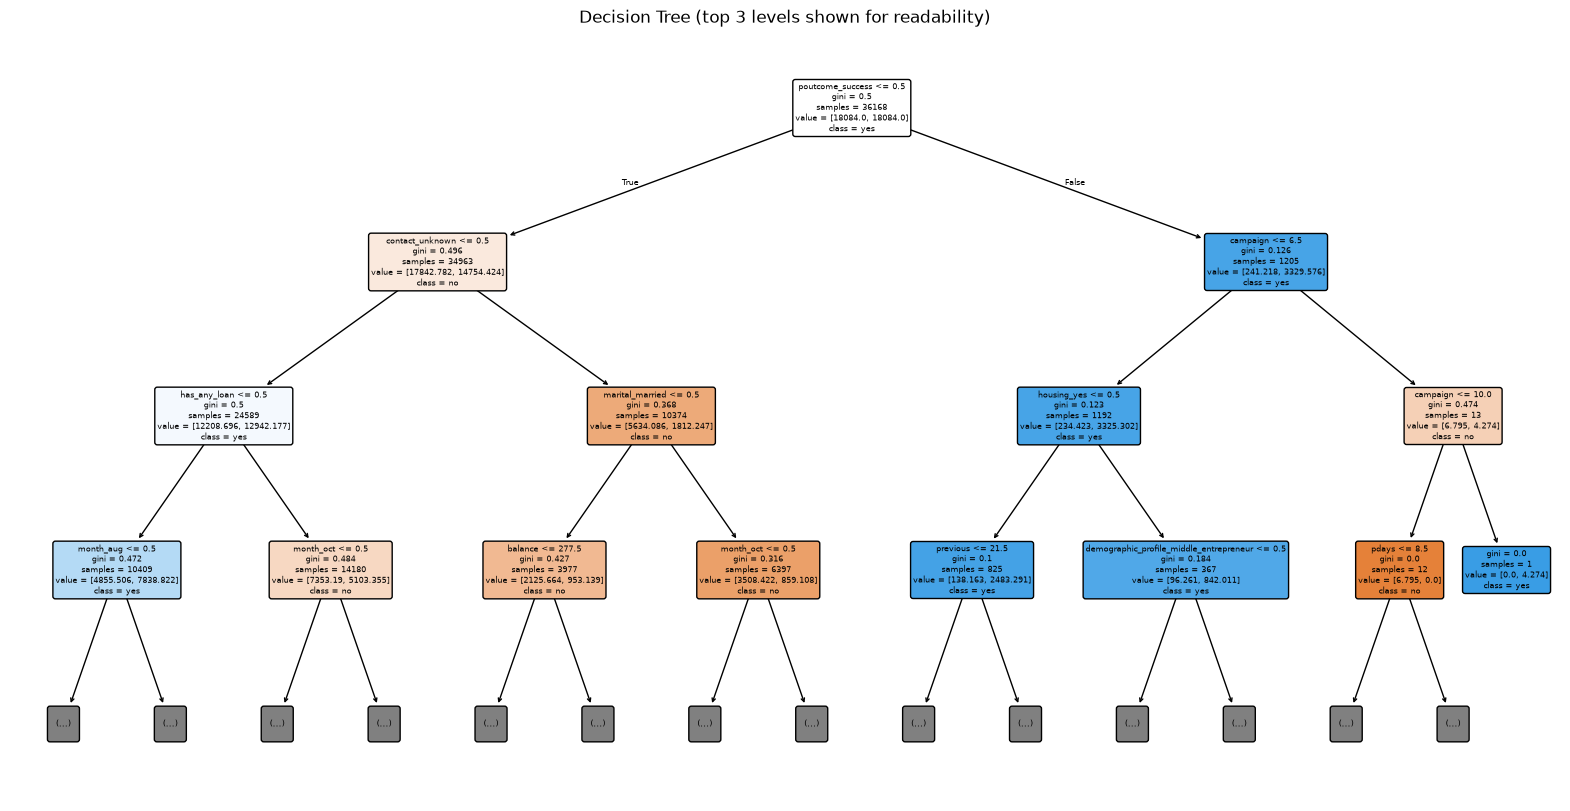

In [67]:
# Decision Tree Visualization
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))
plot_tree(dt, feature_names=X_train_no_duration.columns, class_names=['no', 'yes'], 
          filled=True, rounded=True, fontsize=6, max_depth=3)
plt.title('Decision Tree (top 3 levels shown for readability)')
plt.show()